# Dijagnoza raka dojke: neuronska mreža (MLP)

**Cilj:** klasifikovati tumor kao benigni ili maligni na osnovu 30 mera ćelijskih jezgara.

**Postupak:** zamena nedostajućih vrednosti medijanom, stratifikovana podela, standardizacija fitovana samo na trening skupu, višeslojni perceptron i evaluacija.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score

In [2]:
df = pd.read_csv('data/breast_cancer.csv', na_values=['-', '/', ' ', '', 'NA'])
print(df.shape)
print(df['isBenign'].value_counts())
df.isna().sum()[lambda s: s > 0]

(569, 31)
isBenign
1    357
0    212
Name: count, dtype: int64
mean radius     2
mean texture    2


Obe kolone sa nedostajućim vrednostima nemaju normalnu raspodelu (Shapiro-Wilk p < 0,05), pa ih menjamo medijanom.

In [3]:
for col in ['mean radius', 'mean texture']:
    print(col, 'Shapiro p =', shapiro(df[col].dropna()).pvalue)
    df[col] = df[col].fillna(df[col].median())

mean radius Shapiro p = 3.792843427944608e-14
mean texture Shapiro p = 9.007535733256736e-08


## Podela i standardizacija
Neuronske mreže se treniraju gradijentnim spustom i potrebni su im standardizovani ulazi. Scaler se **fituje samo na trening skupu**, a zatim primenjuje na test skup, da ne bi došlo do curenja podataka.

In [4]:
X = df.drop(columns='isBenign')
y = df['isBenign']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Model
Arhitektura mreže je **30-64-32-1**: ulazni sloj ima 30 neurona, mreža ima dva skrivena sloja (64 i 32 neurona, ReLU aktivacija), a izlazni sloj jedan neuron.

Tokom treninga se ponavljaju sledeći koraci:
1. **Forward propagation:** ulazi prolaze kroz mrežu i računaju se predikcije.
2. **Računanje greške:** predikcije se porede sa stvarnim vrednostima.
3. **Backpropagation:** određuje se kako svaki parametar utiče na grešku.
4. **Ažuriranje parametara:** težine i bias vrednosti se menjaju optimizacionim algoritmom (SGD) da bi se greška smanjila.

Jedan prolazak kroz ceo trening skup je jedna epoha.

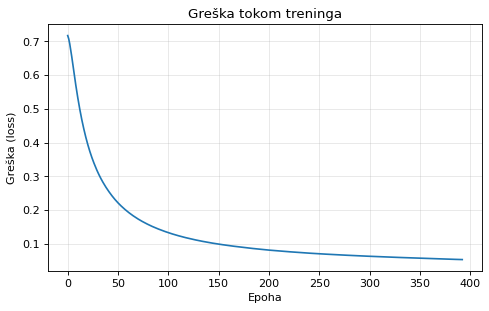

In [5]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), solver='sgd', max_iter=1000, random_state=42)
mlp.fit(X_train, y_train)

plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_)
plt.xlabel('Epoha'); plt.ylabel('Greška (loss)'); plt.title('Greška tokom treninga'); plt.grid(alpha=0.3)
plt.show()

## Evaluacija

              precision    recall  f1-score   support

     Maligni      0.953     0.976     0.965        42
     Benigni      0.986     0.972     0.979        72

    accuracy                          0.974       114
   macro avg      0.970     0.974     0.972       114
weighted avg      0.974     0.974     0.974       114

ROC-AUC: 0.996


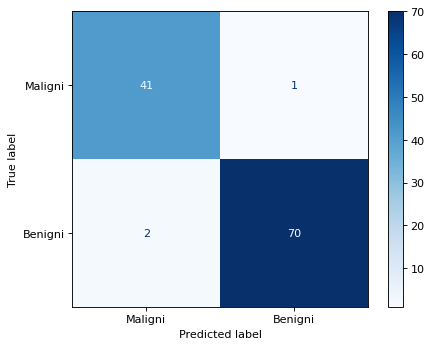

In [6]:
y_pred = mlp.predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Maligni', 'Benigni']).plot(cmap=plt.cm.Blues)
plt.show()
print(classification_report(y_test, y_pred, target_names=['Maligni', 'Benigni'], digits=3))
print('ROC-AUC:', round(roc_auc_score(y_test, mlp.predict_proba(X_test)[:, 1]), 3))

## Zaključak
- Mreža odlično razdvaja benigne i maligne tumore na podacima koje nije videla: **tačnost 97,4%**, **ROC-AUC 0,996**.
- U medicini je najvažniji **recall za maligne tumore**: propušten maligni tumor (lažno negativan) je mnogo skuplja greška od lažne uzbune, pa prag odlučivanja treba birati imajući to u vidu.